# IADS5 · TP integrador — Ortelana Textil
### Actividad 15 · Selección final y ajuste fino

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 15 · Selección final y ajuste fino

**Qué se espera:** Revisá reproducibilidad de notebooks, reentrená con todos los datos de entrenamiento usando la configuración seleccionada, evaluá sobre test y cerrá README. Versioná el estado final.

**Evidencia a entregar:** Notebooks verificados; README; commit `release: modelo candidato final`; tag `v1.0`.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Año", "Metros1", "Metros2"]   # sin Sucursal_ID ni Tela_ID (actividad 13)
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 3) | Test: (657, 3)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

num_cols = ["Año", "Metros1", "Metros2"]

def crear_pipeline_final(modelo):
    """Solo variables de volumen y año: imputar con la mediana (sin escalar, RF es invariante a la escala).
    Sucursal_ID y Tela_ID no entran al modelo: con un par conocido alcanza con su formato histórico."""
    preprocesador = ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median"))]), num_cols),
    ], verbose_feature_names_out=False)
    return Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo)])


In [3]:
# 15.1 Reproducibilidad
# La partición ya se verificó en la primera celda: coincide con particion_train_test.csv
print("Partición:", len(train), "train /", len(test), "test")

def crear_modelo_final():
    """Mejor configuración del GridSearchCV de la actividad 14 (F1 macro CV agrupada por par = 0.8868)."""
    return crear_pipeline_final(RandomForestClassifier(n_estimators=300, max_features=3, min_samples_leaf=3,
                                                       random_state=RANDOM_STATE, n_jobs=-1))

# Entrenar dos veces con la misma configuración tiene que dar exactamente las mismas predicciones
pred_a = crear_modelo_final().fit(X_train, y_train).predict(X_test)
pred_b = crear_modelo_final().fit(X_train, y_train).predict(X_test)
print("Entrenamiento determinista:", (pred_a == pred_b).all())

Partición: 2628 train / 657 test


Entrenamiento determinista: True


In [4]:
# 15.2 Reentrenamiento con TODO el conjunto de entrenamiento y la configuración seleccionada
modelo_final = crear_modelo_final()
modelo_final.fit(X_train, y_train)
print("Modelo final entrenado con", len(X_train), "registros")

Modelo final entrenado con 2628 registros


Accuracy test: 0.9087
F1 macro test: 0.9107

              precision    recall  f1-score   support

           B     0.9722    0.9589    0.9655       146
           C     0.9527    0.9360    0.9443       172
           M     0.8092    0.9150    0.8589       153
           S     0.9123    0.8387    0.8739       186

    accuracy                         0.9087       657
   macro avg     0.9116    0.9122    0.9107       657
weighted avg     0.9122    0.9087    0.9092       657



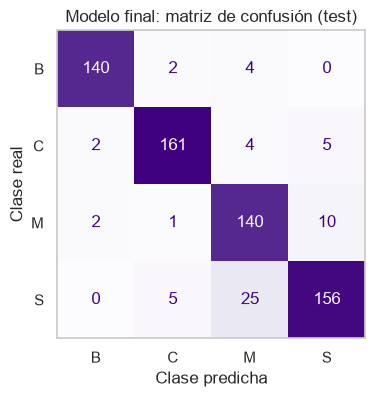

,F1 macro
"Selección: GridSearchCV con CV agrupada por par (5 folds, train)",0.8868
"Referencia: misma configuración con CV aleatoria (5 folds, train)",0.9094
Final: test (una sola vez),0.9107


In [5]:
# 15.3 Evaluación final ÚNICA sobre test
pred_final = modelo_final.predict(X_test)
print("Accuracy test:", round(accuracy_score(y_test, pred_final), 4))
print("F1 macro test:", round(f1_score(y_test, pred_final, average="macro"), 4))
print()
print(classification_report(y_test, pred_final, digits=4))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, ax=ax, cmap="Purples", colorbar=False)
ax.set(title="Modelo final: matriz de confusión (test)", xlabel="Clase predicha", ylabel="Clase real")
ax.grid(False)
plt.show()

pd.DataFrame({"F1 macro": [0.8868, 0.9094, f1_score(y_test, pred_final, average="macro")]},
             index=["Selección: GridSearchCV con CV agrupada por par (5 folds, train)",
                    "Referencia: misma configuración con CV aleatoria (5 folds, train)",
                    "Final: test (una sola vez)"]).round(4)

In [6]:
# 15.4 README final (archivo README.md del repositorio)
with open("README.md", encoding="utf-8") as archivo:
    print(archivo.read())

# Ortelana Textil — Clasificación de `Format_Reporte`

Trabajo práctico integrador grupal IADS5 (Procesamiento de Aprendizaje Automático).

**Integrantes:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma

## Problema
- **Principal:** clasificación multiclase de `Format_Reporte` (B, C, M, S) con `Año, Metros1, Metros2`. El modelo final no usa
  `Sucursal_ID` ni `Tela_ID`: el formato es constante para cada par (Sucursal, Tela), así que para un par conocido no hace
  falta machine learning (alcanza con su formato histórico). El modelo tiene sentido para pares nuevos y se valida para ese uso.
- **Secundario (regresión):** `volumen_anual_metros` (suma anual de los metros con dato de cada fila) con `Sucursal_ID, Tela_ID, Año`, usando `Ridge(alpha=1)`. No usamos `Metros2` porque mide un período distinto según el formato (un mes en M, un semestre en S y C) y no es comparable entre filas. Las columnas `Metros1`–`Metros12` no ent

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Reproducibilidad:**
  - Regeneramos la partición con la misma semilla y comprobamos que coincide fila por fila con `particion_train_test.csv`.
  - Entrenamos dos veces la misma configuración y obtuvimos predicciones idénticas, porque todas las semillas están fijadas en 42.
  - Para la ejecución completa, el notebook corre de principio a fin sin errores con `nbconvert --execute`.
- **Reentrenamiento:** con **todo el conjunto de entrenamiento** (2.628 filas), usando la configuración elegida por GridSearchCV (`n_estimators=300`, `max_features=3`, `min_samples_leaf=3`) y solo `Año`, `Metros1` y `Metros2`.
- **Evaluación final:** una única vez sobre el 20% de test.
- **README:** queda cerrado, con el problema, la estructura, la reproducción, los resultados finales, las limitaciones y las versiones.

**Interpretación de los resultados:**
- **Resultado final en test:** **F1 macro = 0,9107** y **accuracy = 0,9087** sobre 657 registros, en línea con la CV aleatoria de la misma configuración (0,909).
- **Para pares nuevos**, la estimación es la de la CV agrupada (0,887): unos 2 puntos menos, porque todos los pares de test aparecen en train. Que la brecha sea tan chica confirma que el modelo ya no depende de memorizar pares.
- **Por clase:**
  - B: F1 0,966.
  - C: 0,944.
  - M: 0,859 (recall 0,915, precision 0,809).
  - S: 0,874 (recall 0,839).
- **Errores:** son 60 de 657 y repiten el patrón del análisis fuera de fold. El más frecuente es S→M (25 casos): M recibe falsos positivos de otras clases y S es la clase con menor recall.

**Pregunta de análisis:** ¿Qué resultados son finales y cuáles provinieron de la búsqueda de modelos?
- **Finales:** solo las métricas de la celda 15.3 (F1 macro 0,9107, accuracy 0,9087, reporte por clase y matriz de confusión). Corresponden al modelo final reentrenado con todo el train y evaluado en test una sola vez después de cerrar todas las decisiones.
- **De la búsqueda (no son estimaciones imparciales):**
  - Las medias de CV de las actividades 7–14, incluido el 0,8868 de GridSearchCV, que es el máximo entre 27 candidatos y por eso es levemente optimista.
  - Las métricas de test "históricas" de las actividades 2–13. Las pide el enunciado, pero al consultarlas repetidamente el test dejó de ser completamente ajeno a las decisiones.
- **Para mitigar ese sesgo:** elegimos el modelo y los hiperparámetros solo con CV.

**Limitaciones o mejoras posibles:**
- El test solo contiene pares (Sucursal, Tela) conocidos y años dentro del rango 2016–2025. Para pares nuevos, la referencia es la CV agrupada (~0,89).
- Para pares conocidos no hace falta el modelo: el formato histórico del par es exacto.
- Para el uso productivo convendría reentrenar con train + test una vez cerrada la evaluación.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]